In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
PROJECT_DIR = '/content/drive/My Drive/MyDrive/fintechathon'
os.makedirs(PROJECT_DIR, exist_ok=True)
print(f"Project folder: {PROJECT_DIR}")

Mounted at /content/drive
Project folder: /content/drive/My Drive/MyDrive/fintechathon


In [ ]:
!pip install -q google-genai ipywidgets

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 42.0 MB/s eta 0:00:00


In [ ]:
import numpy as np
import pandas as pd
from datetime import datetime, timedelta

def make_income(n=180, trend=0.0, volatility=15, shock_rate=0.05, seed=42):
    """Generate realistic gig-worker daily income."""
    np.random.seed(seed)
    days = np.arange(n)
    weekly = 15 * np.sin(2 * np.pi * days / 7)
    base   = 80 + trend * days
    noise  = np.random.normal(0, volatility, n)
    shocks = np.where(np.random.random(n) < shock_rate, -50, 0)
    income = np.clip(base + weekly + noise + shocks, 0, None)
    dates  = [datetime(2025,1,1) + timedelta(days=i) for i in range(n)]
    return pd.DataFrame({"date": dates, "income": income.round(2)})

SCENARIOS = {
    "stable":   lambda: make_income(trend= 0.00, volatility=10, shock_rate=0.02),
    "growing":  lambda: make_income(trend= 0.20, volatility=12, shock_rate=0.03),
    "declining":lambda: make_income(trend=-0.20, volatility=12, shock_rate=0.05),
    "volatile": lambda: make_income(trend= 0.00, volatility=25, shock_rate=0.10),
}

df = SCENARIOS["volatile"]()
print(df.head())
print(f"\nMean income: ${df['income'].mean():.2f}")
print(f"Std dev:     ${df['income'].std():.2f}")

        date  income
0 2025-01-01   92.42
1 2025-01-02   88.27
2 2025-01-03  110.82
3 2025-01-04   74.58
4 2025-01-05   67.64

Mean income: $72.73
Std dev:     $28.49


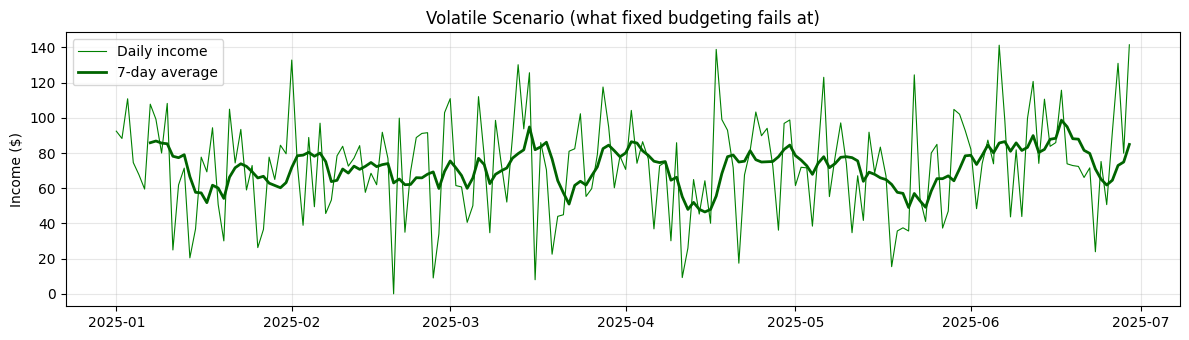

In [ ]:
import matplotlib.pyplot as plt

def plot_income(df, title="Income Pattern"):
    fig, ax = plt.subplots(figsize=(12, 3.5))
    ax.plot(df["date"], df["income"], color="green", lw=0.8, label="Daily income")
    ax.plot(df["date"], df["income"].rolling(7).mean(), color="darkgreen",
            lw=2, label="7-day average")
    ax.set_ylabel("Income ($)")
    ax.set_title(title)
    ax.legend()
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

plot_income(df, "Volatile Scenario (what fixed budgeting fails at)")

In [ ]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

def predict_income(income_series, horizon=7):
    """Forecast + 95% confidence interval via residual bootstrap."""
    model = ExponentialSmoothing(income_series, trend=None, seasonal=None).fit()
    # Removed .values and wrapped in np.array to ensure compatibility
    forecast = np.array(model.forecast(horizon))
    sigma = np.std(model.resid)
    lower = np.maximum(forecast - 1.96 * sigma, 0)
    upper = forecast + 1.96 * sigma
    return forecast, lower, upper, sigma

forecast, lower, upper, sigma = predict_income(
    df["income"].values, horizon=7
)
predicted_monthly = forecast.sum() * 4.33
print(f"Predicted weekly income:  ${forecast.sum():.2f}")
print(f"Predicted monthly income: ${predicted_monthly:.2f}")
print(f"Margin of error:          +/- ${1.96*sigma:.2f}/day")

Predicted weekly income:  $509.09
Predicted monthly income: $2204.35
Margin of error:          +/- $55.69/day


In [ ]:
def default_categories():
    return {
        "rent":          {"cap": 800, "floor": 800, "essential": True},
        "utilities":     {"cap": 120, "floor": 100, "essential": True},
        "food":          {"cap": 400, "floor": 250, "essential": True},
        "transport":     {"cap": 200, "floor": 100, "essential": False},
        "discretionary": {"cap": 300, "floor":   0, "essential": False},
    }

def reallocate(planned_income, predicted_income, categories,
               threshold=0.10):
    """Deterministic rules. No LLM involved."""
    shortfall_pct = (planned_income - predicted_income) / planned_income
    if shortfall_pct < threshold:
        return None

    reduction = planned_income - predicted_income
    cuts = {}

    # 1. Cut non-essentials first
    for name in ["discretionary", "transport"]:
        if reduction <= 0: break
        cat = categories[name]
        cut = min(cat["cap"] - cat["floor"], reduction)
        if cut > 0:
            cat["cap"] -= cut
            cuts[name] = round(float(cut), 2)
            reduction -= cut

    # 2. Then essentials down to floor (food only)
    if reduction > 0:
        cat = categories["food"]
        cut = min(cat["cap"] - cat["floor"], reduction)
        if cut > 0:
            cat["cap"] -= cut
            cuts["food"] = round(float(cut), 2)
            reduction -= cut

    return {
        "shortfall_pct": round(shortfall_pct, 4),
        "cuts": cuts,
        "new_caps": {k: float(v["cap"]) for k, v in categories.items()},
        "uncovered": round(max(0, reduction), 2),
        "rule_version": "1.0",
    }

In [ ]:
from google.colab import userdata

try:
    from google import genai
    _client = genai.Client(api_key=userdata.get("GEMINI_API_KEY"))
    HAS_LLM = True
except Exception as e:
    print(f"LLM unavailable. Using fallback.")
    HAS_LLM = False

def fallback_explanation(decision):
    if decision is None:
        return "Income is on track. No changes needed."
    cuts_text = ", ".join(
        f"${v:.0f} from {k}" for k, v in decision["cuts"].items()
    )
    return (
        f"Heads up: we predict income will be "
        f"{decision['shortfall_pct']*100:.0f}% below plan next month. "
        f"We cut {cuts_text}. Rent and utilities are protected. "
        f"Try pausing subscriptions this week."
    )

def explain(decision):
    if not HAS_LLM or decision is None:
        return fallback_explanation(decision)

    prompt = f"""You are a compassionate financial assistant.
A deterministic engine made this decision: {decision}
Explain in 3-4 sentences. Use ONLY these numbers.
Give 3 tips. Under 200 words. Do not suggest loans. Tone: calm."""

    response = _client.models.generate_content(
        model="gemini-2.0-flash",
        contents=prompt,
    )
    return response.text.strip()

LLM unavailable. Using fallback.


/tmp/ipykernel_1310/3236934466.py:6: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  "timestamp": datetime.utcnow().isoformat(),


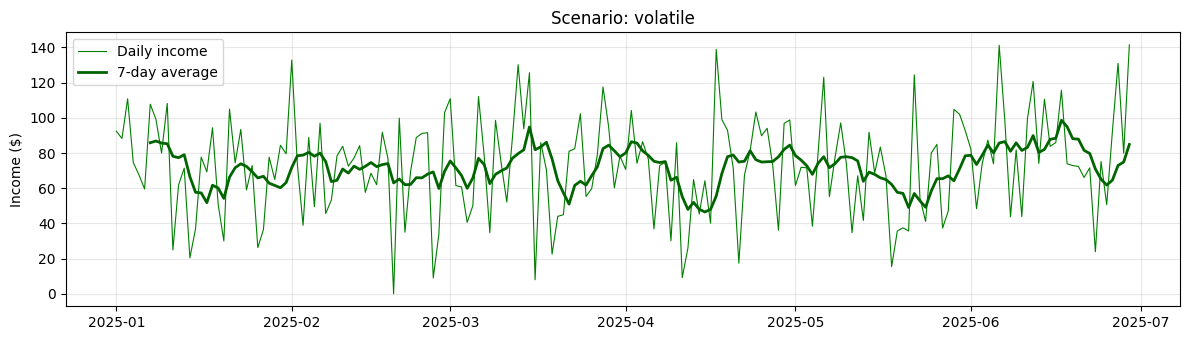

Planned:   $2,509.09
Predicted: $2,204.35
Decision: Cuts {'discretionary': 300.0, 'transport': 4.74}
Heads up: we predict income will be 12% below plan next month. We cut $300 from discretionary, $5 from transport. Rent and utilities are protected. Try pausing subscriptions this week.


{'shortfall_pct': np.float64(0.1215),
 'cuts': {'discretionary': 300.0, 'transport': 4.74},
 'new_caps': {'rent': 800.0,
  'utilities': 120.0,
  'food': 400.0,
  'transport': 195.25528246543809,
  'discretionary': 0.0},
 'uncovered': 0,
 'rule_version': '1.0'}

In [ ]:
import json
AUDIT_LOG = []

def log_event(event_type, payload):
    AUDIT_LOG.append({
        "timestamp": datetime.utcnow().isoformat(),
        "type": event_type,
        **payload,
    })

def run_agent(scenario, threshold=0.10):
    df = SCENARIOS[scenario]()
    forecast, lower, upper, sigma = predict_income(
        df["income"].values, horizon=7
    )
    predicted_monthly = forecast.sum() * 4.33
    planned_income = df["income"].tail(30).mean() * 30

    categories = default_categories()
    decision = reallocate(
        planned_income, predicted_monthly, categories, threshold
    )
    explanation = explain(decision)

    log_event("agent_run", {
        "scenario": scenario,
        "planned_income": round(planned_income, 2),
        "predicted_monthly": round(predicted_monthly, 2),
        "decision": decision,
        "explanation": explanation,
    })

    plot_income(df, f"Scenario: {scenario}")
    print(f"Planned:   ${planned_income:,.2f}")
    print(f"Predicted: ${predicted_monthly:,.2f}")
    if decision:
        print(f"Decision: Cuts {decision['cuts']}")
        print(explanation)

    return decision

run_agent("volatile")

In [17]:
import ipywidgets as widgets
from IPython.display import display, clear_output

scenario_w  = widgets.Dropdown(options=list(SCENARIOS), value="volatile", description="Scenario:")
threshold_w = widgets.FloatSlider(
    value=0.10, min=0.05, max=0.30, step=0.01,
    description="Alert at:", readout_format=".0%"
)
run_w       = widgets.Button(description="Run Agent", button_style="success")
output      = widgets.Output()

def on_run(_):
    with output:
        clear_output()
        decision = run_agent(scenario_w.value, threshold_w.value)
        if decision is not None:
            approve_w = widgets.Button(description="Approve", button_style="info")
            reject_w  = widgets.Button(description="Reject",  button_style="warning")
            log_display = widgets.Output()

            def on_approve(_):
                log_event("user_approval", {"decision": decision})
                with log_display:
                    clear_output()
                    print("Plan approved and logged.")

            def on_reject(_):
                log_event("user_rejection", {"decision": decision})
                with log_display:
                    clear_output()
                    print("Plan rejected and logged.")

            approve_w.on_click(on_approve)
            reject_w.on_click(on_reject)
            display(widgets.HBox([approve_w, reject_w]), log_display)

run_w.on_click(on_run)
display(scenario_w, threshold_w, run_w, output)

Dropdown(description='Scenario:', index=3, options=('stable', 'growing', 'declining', 'volatile'), value='vola…

FloatSlider(value=0.1, description='Alert at:', max=0.3, min=0.05, readout_format='.0%', step=0.01)

Button(button_style='success', description='Run Agent', style=ButtonStyle())

Output()

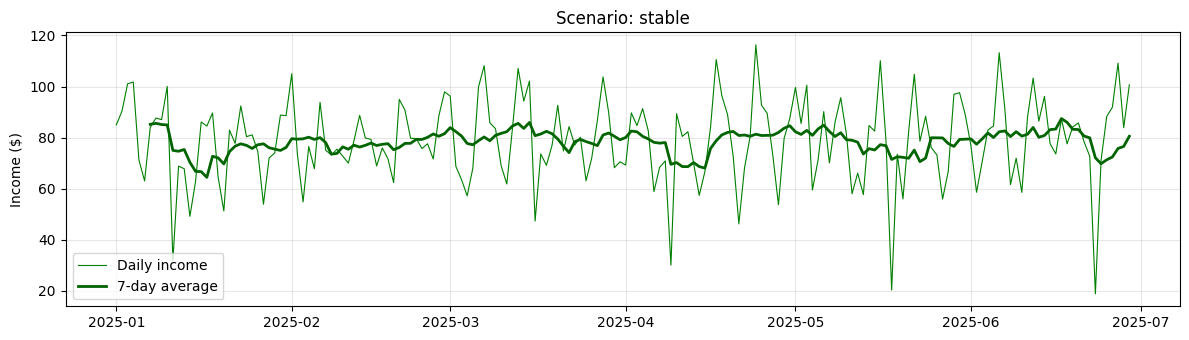

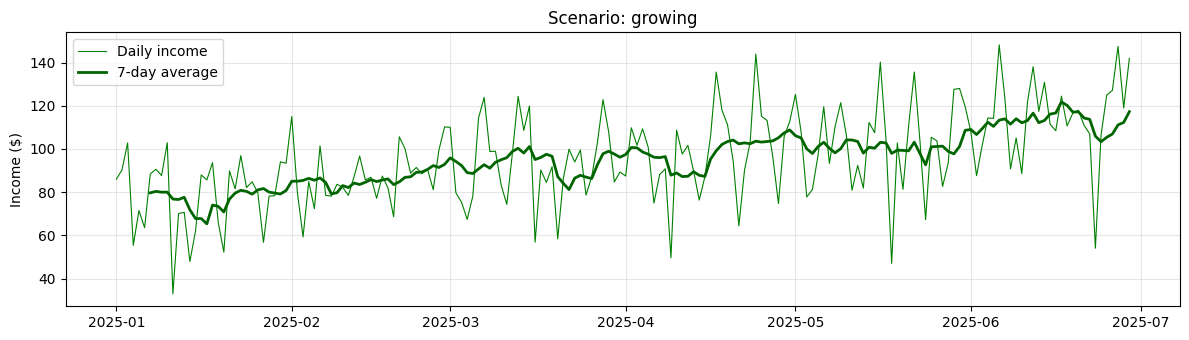

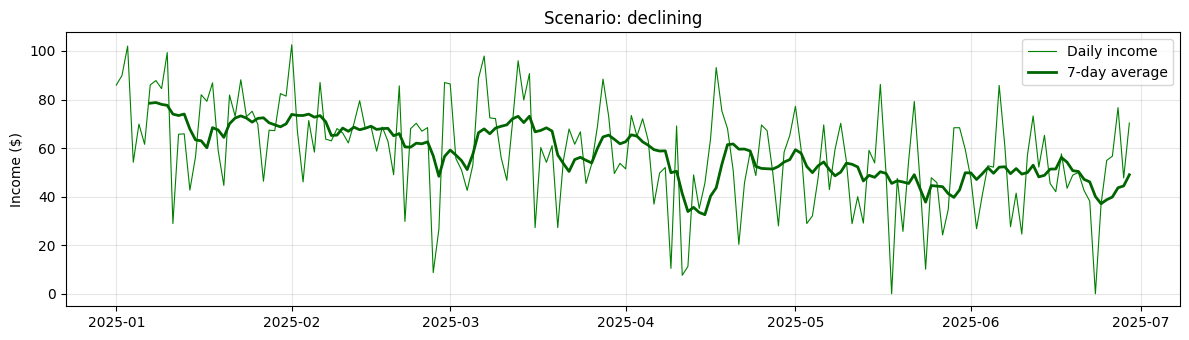

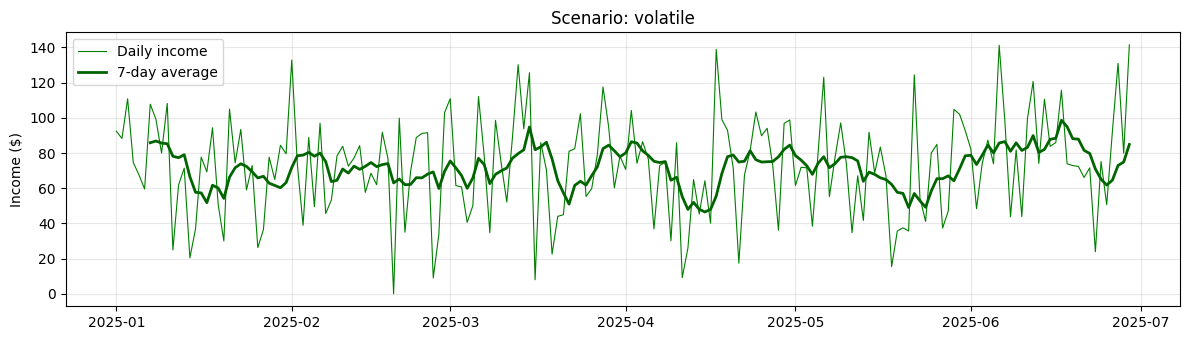

All files saved to your Google Drive:
['audit_log.json', 'plot_stable.png', 'plot_growing.png', 'plot_declining.png', 'plot_volatile.png']


In [ ]:
import json
audit_path = os.path.join(PROJECT_DIR, "audit_log.json")
with open(audit_path, "w") as f:
    json.dump(AUDIT_LOG, f, indent=2)

for scenario in SCENARIOS:
    df_s = SCENARIOS[scenario]()
    plot_income(df_s, f"Scenario: {scenario}")
    plt.savefig(os.path.join(PROJECT_DIR, f"plot_{scenario}.png"), dpi=120)
    plt.close()

print("All files saved to your Google Drive:")
print(os.listdir(PROJECT_DIR))